### Training a CNN to predict sleep stages from EEG Signals.

In [33]:
import os 
import glob 

import numpy as np
import matplotlib.pyplot as plt 

import torch 
import torch.nn as nn 

from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score, confusion_matrix

import mne # EEG package (ie. reading edf & hypnogram files)

In [34]:
data_dir = "data/sleep_data/sleep-cassette"

#store the filepath of specfic files join (___, this) as a list. 
psg_files = sorted(glob.glob(os.path.join(data_dir, '*PSG.edf')))
hypnogram_files = sorted(glob.glob(os.path.join(data_dir, '*Hypnogram.edf')))

#### Data Exploration

In [35]:
# loading oen of the raw time-series psg data
raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)

/tmp/ipykernel_4209/2355177315.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
/tmp/ipykernel_4209/2355177315.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
/tmp/ipykernel_4209/2355177315.py:2: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)


In [36]:
raw_edf 

#7 channels, only 2 for EEG

'''
ch1 EEG Fpz-Cz
ch2 EEG Pz-Oz
ch3 EOG Horizontal # Tracking eye movement
ch4 Resp oro-nasal # Measurments of air movement through the nose and mouth
ch5 EMG submental # Tracking electrical signal under chin 
ch6 Temp rectal # Temprature of body
ch7 Event marker #inserting timestamped labels into eeg recordign when 
                # there is something meaningful to mark 
'''

'\nch1 EEG Fpz-Cz\nch2 EEG Pz-Oz\nch3 EOG Horizontal # Tracking eye movement\nch4 Resp oro-nasal # Measurments of air movement through the nose and mouth\nch5 EMG submental # Tracking electrical signal under chin \nch6 Temp rectal # Temprature of body\nch7 Event marker #inserting timestamped labels into eeg recordign when \n                # there is something meaningful to mark \n'

In [37]:
# getting actual eeg data from th edf file, use .get_data()
eeg_data = raw_edf.get_data()

In [38]:
eeg_data

array([[ 5.01684982e-06, -2.57875458e-06,  1.35970696e-06, ...,
         5.29816850e-06, -4.64175824e-06,  6.61098901e-06],
       [-2.46739927e-06,  1.46739927e-06, -4.09890110e-06, ...,
        -3.04322344e-06, -3.71501832e-06,  1.75531136e-06],
       [ 1.65086691e-05,  1.60158730e-05,  9.60952381e-06, ...,
         6.97306471e-05,  8.05721612e-05,  1.02255189e-04],
       ...,
       [ 3.55200000e-06,  3.55321564e-06,  3.55442478e-06, ...,
         3.54832977e-06,  3.54955549e-06,  3.55077942e-06],
       [ 3.72064516e+01,  3.72051596e+01,  3.72039072e+01, ...,
         3.72105629e+01,  3.72091535e+01,  3.72077830e+01],
       [ 9.20000000e+02,  9.19950203e+02,  9.19892908e+02, ...,
         9.20104028e+02,  9.20076946e+02,  9.20042260e+02]],
      shape=(7, 7950000))

In [39]:
# getting eeg of only first channel 

eeg_channel1 = eeg_data[0]

# 0 = 1st channel, 6 = 7th channel

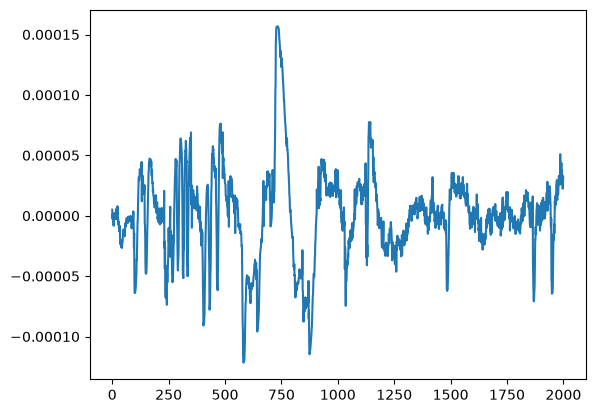

In [40]:
plt.plot(eeg_channel1[:2000])

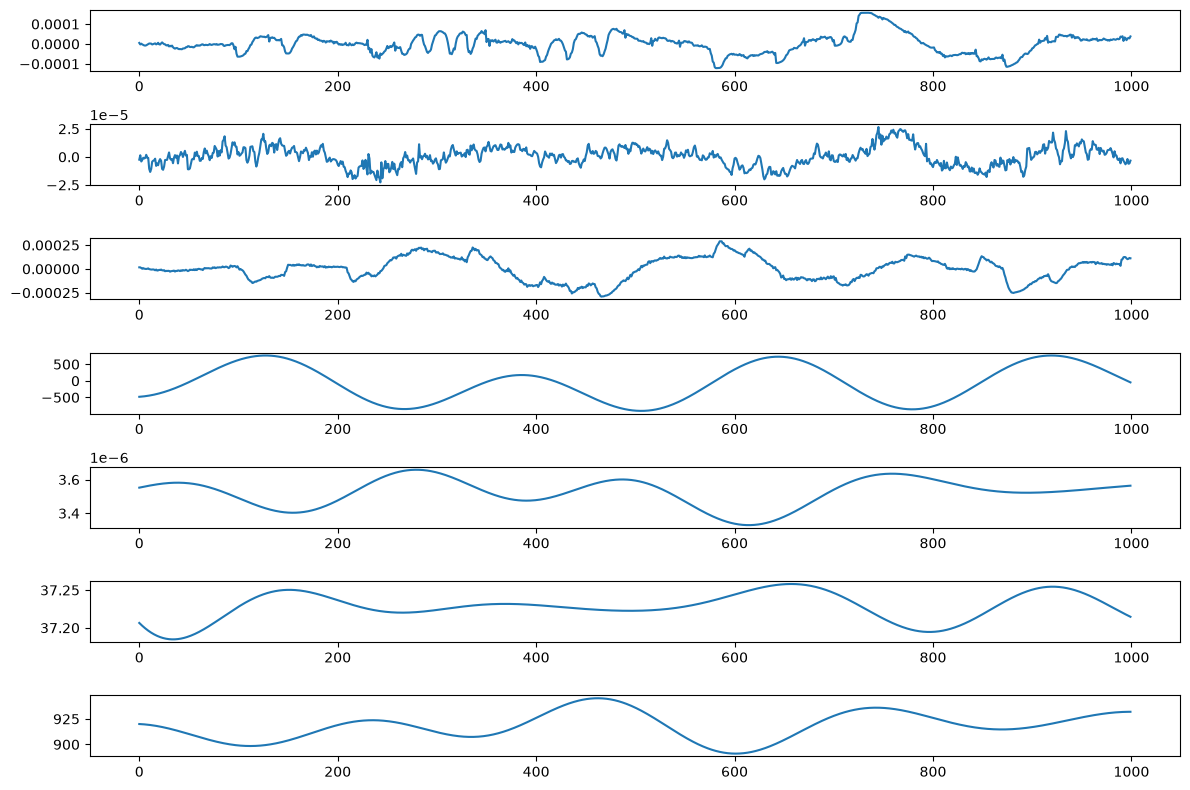

In [41]:
#plotting all the data to see the different channels that we have
fig, axs = plt.subplots(nrows=7, ncols=1, figsize=(12, 8))

for i, ax in enumerate(axs):
    ax.plot(eeg_data[i][:1000])

plt.tight_layout()

In [42]:
# proper visualization wiht proper labeling for the 2 eeg channels 
eeg_channels = ['EEG Fpz-Cz', 'EEG Pz-Oz']

eeg_data = raw_edf.get_data(picks=eeg_channels)

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

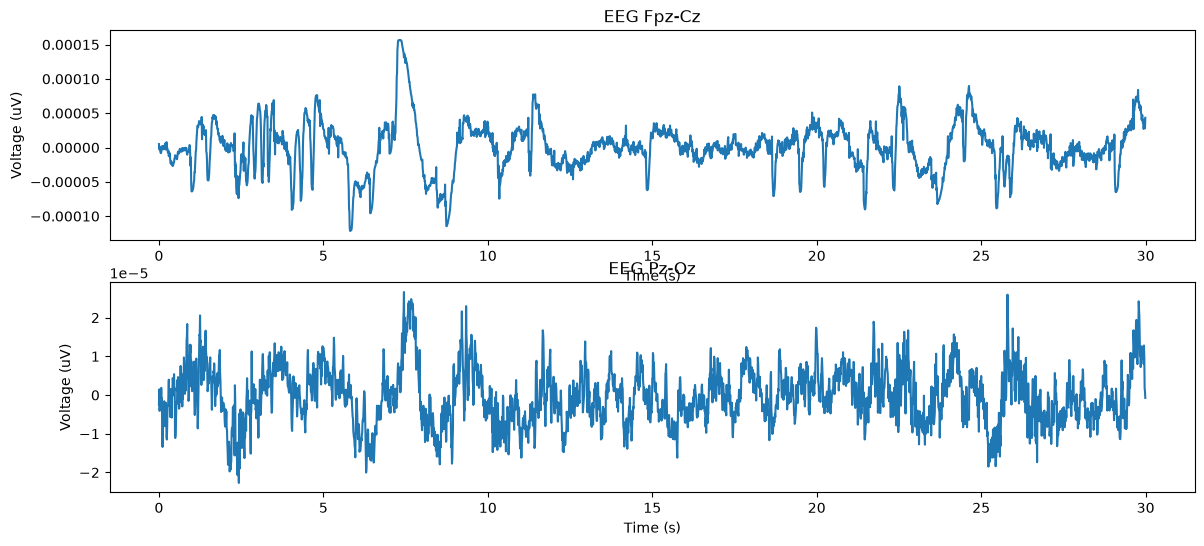

In [43]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(14, 6))


fs = 100 # Sampling frequency
N = 3000 # for 30s of data 

for i, ax in enumerate(axs):
    x = np.arange(N) / fs # -> 0.01s

    ax.plot(x, eeg_data[i][:N])
    ax.set_title(eeg_channels[i])
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Voltage (uV)')

plt.tight_layout

Ground truth (hypnogram files)

In [44]:
annotations = mne.read_annotations(hypnogram_files[0])

In [45]:
annotations.onset

array([    0., 30630., 30750., 31140., 31170., 31200., 31350., 31380.,
       31440., 31500., 31530., 31650., 31680., 31800., 31830., 31890.,
       31950., 32070., 32100., 32130., 32250., 32460., 32490., 32550.,
       32670., 32700., 32850., 32910., 32940., 32970., 33000., 33120.,
       33270., 33300., 33330., 33390., 33420., 33510., 35400., 35430.,
       35640., 35700., 35790., 35940., 35970., 36840., 37020., 37260.,
       37290., 37410., 37500., 37530., 38460., 38490., 38520., 38580.,
       38610., 38640., 38670., 38700., 38730., 38760., 38910., 38970.,
       39060., 39120., 39150., 39180., 39240., 39300., 39480., 39540.,
       39570., 39600., 39870., 39900., 39960., 39990., 40200., 40230.,
       40290., 40320., 40500., 41370., 41400., 41460., 41490., 41610.,
       42480., 42510., 42540., 42570., 42870., 42900., 43290., 43320.,
       43350., 43380., 43410., 43590., 43680., 43710., 43920., 43980.,
       44010., 44040., 44220., 44280., 44340., 44400., 44520., 44640.,
      

In [46]:
annotations.duration

array([3.063e+04, 1.200e+02, 3.900e+02, 3.000e+01, 3.000e+01, 1.500e+02,
       3.000e+01, 6.000e+01, 6.000e+01, 3.000e+01, 1.200e+02, 3.000e+01,
       1.200e+02, 3.000e+01, 6.000e+01, 6.000e+01, 1.200e+02, 3.000e+01,
       3.000e+01, 1.200e+02, 2.100e+02, 3.000e+01, 6.000e+01, 1.200e+02,
       3.000e+01, 1.500e+02, 6.000e+01, 3.000e+01, 3.000e+01, 3.000e+01,
       1.200e+02, 1.500e+02, 3.000e+01, 3.000e+01, 6.000e+01, 3.000e+01,
       9.000e+01, 1.890e+03, 3.000e+01, 2.100e+02, 6.000e+01, 9.000e+01,
       1.500e+02, 3.000e+01, 8.700e+02, 1.800e+02, 2.400e+02, 3.000e+01,
       1.200e+02, 9.000e+01, 3.000e+01, 9.300e+02, 3.000e+01, 3.000e+01,
       6.000e+01, 3.000e+01, 3.000e+01, 3.000e+01, 3.000e+01, 3.000e+01,
       3.000e+01, 1.500e+02, 6.000e+01, 9.000e+01, 6.000e+01, 3.000e+01,
       3.000e+01, 6.000e+01, 6.000e+01, 1.800e+02, 6.000e+01, 3.000e+01,
       3.000e+01, 2.700e+02, 3.000e+01, 6.000e+01, 3.000e+01, 2.100e+02,
       3.000e+01, 6.000e+01, 3.000e+01, 1.800e+02, 

In [47]:
annotations.description

array(['Sleep stage W', 'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 3',
       'Sleep stage 4', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 3',
       'Sleep stage 4', 'Sleep stage W', 'Sleep stage 3', 'Sleep stage 2',
       'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 3', 'Sleep stage 4',
       'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 2',
       'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4',
       'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4',
       'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 1', 'Sleep stage 3',
       'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage R', 'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 1', 'Sleep stage 2',
       'Sleep stage 3', '

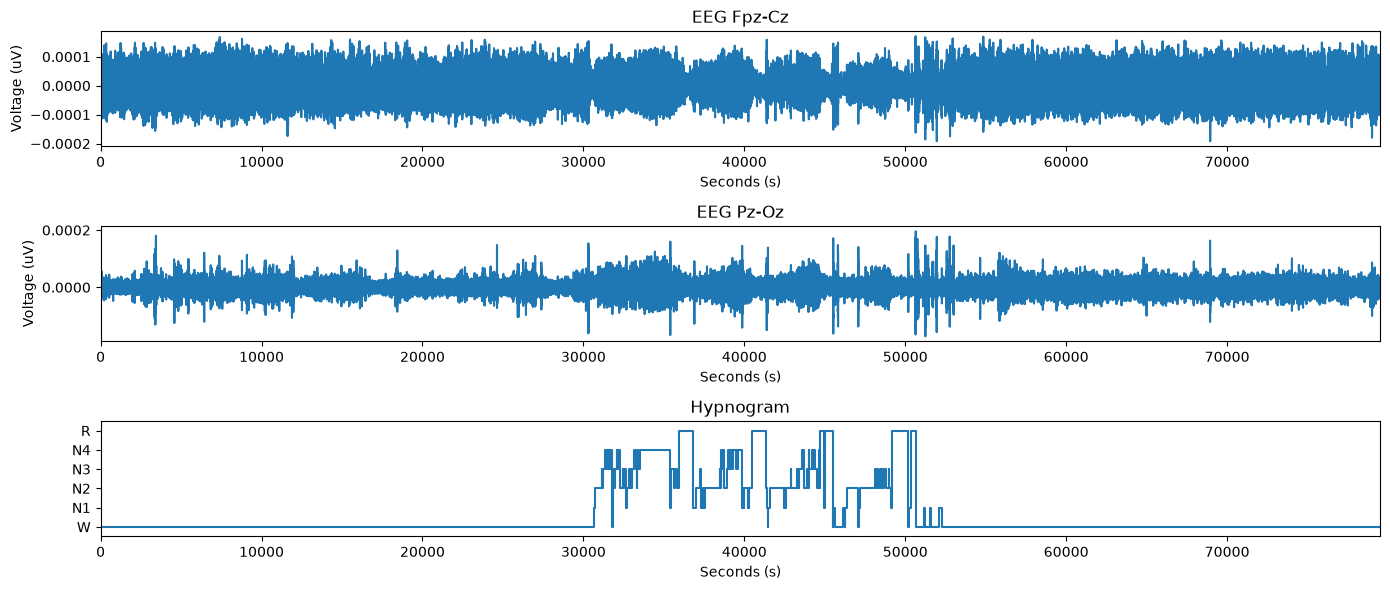

In [48]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(14,6))

fs = 100
N = 7950000

# Axis 1 - EEG
x = np.arange(N) / fs

axs[0].plot(x, eeg_data[0][:N])
axs[0].set_title(eeg_channels[0])
axs[0].set_xlabel('Seconds (s)')
axs[0].set_ylabel('Voltage (uV)')

axs[0].set_xlim(0, N/fs)

# Axis 2 - EEG
x = np.arange(N) / fs

axs[1].plot(x, eeg_data[1][:N])
axs[1].set_title(eeg_channels[1])
axs[1].set_xlabel('Seconds (s)')
axs[1].set_ylabel('Voltage (uV)')

axs[1].set_xlim(0, N/fs)

# Axis 3 - Hypnogram
t_end = N / fs

stage_map = {'Sleep stage W': 0, 'Sleep stage 1': 1, 'Sleep stage 2': 2, 'Sleep stage 3': 3, 'Sleep stage 4': 4, 'Sleep stage R': 5}

x, y = [], []
for o, d, s in zip(annotations.onset, annotations.duration, annotations.description):
    start, end = max(o, 0), min(o + d, t_end)
    stage = stage_map.get(s, np.nan)
    x += [start, end]
    y += [stage, stage]

axs[2].step(x, y, where='post')
axs[2].set_xlim(0, t_end)
axs[2].set_ylim(-0.5, 5.5)
axs[2].set_yticks([0,1,2,3,4,5])
axs[2].set_yticklabels(['W','N1','N2','N3', 'N4', 'R'])
axs[2].set_xlabel('Seconds (s)')
axs[2].set_title('Hypnogram')

plt.tight_layout()

### Data Preperation

2 channels are used EEG Fpz-Cz and EEG Pz-Oz 

In [49]:
len(psg_files)

# 153!! too much it will blow up the ram!, just 25 samples of the data will be used. 

153

In [ ]:
X_data = []
y_data = []
window_length = 3000 # 30s
eeg_channels = ['EEG Fpz-Cz', 'EEG Pz-Oz']  

stage_map = {'Sleep stage W':0, 
            'Sleep stage 1': 1, 
            'Sleep stage 2': 2, 
            'Sleep stage 3': 3, 
            'Sleep stage 4': 4, 
            'Sleep stage R': 5}



for psg_file, hypnogram_file in zip(psg_files[:25], hypnogram_files[:25]):
    raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
    
    # Shape is (2, total_samples)
    eeg_2ch = raw_edf.get_data(picks=eeg_channels)
    annotations = mne.read_annotations(hypnogram_file) 


    for i, (onset, duration, description) in enumerate(zip(annotations.onset, annotations.duration, annotations.description)):
        if description not in stage_map:
            continue

        for segment in range(int(onset * fs ), int(onset * fs  + duration * fs), window_length):
            start_sample = segment
            end_sample = segment + window_length

            if end_sample <= eeg_2ch.shape[1]:
                window = eeg_2ch[:,start_sample:end_sample]

                if window.shape[1] == window_length:
                    X_data.append(window)
                    y_data.append(stage_map[description])

X = np.array(X_data)
y = np.array(y_data)
            


                                                       
    

/tmp/ipykernel_4209/4014929134.py:16: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_4209/4014929134.py:16: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_4209/4014929134.py:16: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_4209/4014929134.py:16: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_4209/4014929134.py:16: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  ra

Analyzing data:

In [ ]:
X.shape

In [ ]:
y.shape

In [ ]:
np.bincount(y)

2 Steps to use the data:
1. Normalize it 
2. train-test split with scikit-learn

In [ ]:
# Normalize per channel across all windows and time steps
mean = X.mean(axis=(0, 2), keepdims=True)
std = X.std(axis=(0, 2), keepdims=True)
X = (X - mean) / std

# 80/20 train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

X_train = torch.FloatTensor(X_train).to(device)
X_test = torch.FloatTensor(X_test).to(device)
y_train = torch.LongTensor(y_train).to(device)
y_test = torch.LongTensor(y_test).to(device)

### Model Training (CNN)

In [ ]:
model = nn.Sequential(
    nn.Conv1d(2, 32, kernel_size=50, stride=6),
    nn.ReLU(),
    nn.MaxPool1d(8),

    nn.Conv1d(32, 64, kernel_size=8),
    nn.ReLU(),
    nn.MaxPool1d(8),
    nn.Flatten(),
    nn.Linear(64 * 6, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 6)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
epochs = 10
batch_size = 64 

for epoch in range(epochs):
    model.train()

    total_loss = 0 

    for i in range(0, len(X_train), batch_size):
        batch_X = X_train[i:i+batch_size].to(device)
        batch_y = y_train[i:i+batch_size].to(device)

        optimizer.zero_grad()

        outputs = model(batch_X)

        loss = criterion(outputs, batch_y)
        loss.backward()

        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(X_train):.4f}")

In [ ]:
model.eval()

with torch.no_grad():
    predictions = model(X_test)
    predicted_classes = torch.argmax(predictions, dim=1).cpu().numpy()

accuracy = accuracy_score(y_test.cpu().numpy(), predicted_classes)

In [ ]:
accuracy

In [ ]:
confusion_matrix(y_test.cpu().numpy(), predicted_classes)